# Detecting Fake Websites with Machine Learning
### Group No: 15
#### F21DL Data Mining and Machine Learning, Group Coursework
---

| Name | Student number | Contribution |
|---|---|---|
| Arafa Mehar | H00561458 | R1, R2 |
| Syed Umraaz | H00557679 | R1, R2 |
| Sakib Dalal | H00549861 | R1, R3 |
| Eric Lazar Antony | H00549103 | R1, R4 |
| Rishab Dhinesh | H | R1, R4 |

---

- Datasets:
    - PhiUSIIL Phishing URL Dataset, UCI Machine Learning Repository (ID 967), CC BY 4.0
    - Image CNN Dataset

---

## Notebook Index
All of the code for requirements R1 to R4 is in this notebook.
1. The questions and the hypotheses (R1)
2. Loading and cleaning the data (R2)
3. Looking at the data with graphs (R2)
4. Choosing the features (R2)
5. Clustering (R2)
6. The classical models (R3)
7. The decision tree (R3)
8. The neural networks (R4)
9. The final comparison and the conclusion
   
---


## Imports and settings

In [80]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

TEST_SIZE = 0.30
CLASS_NAMES = ["Phishing", "Legitimate"]

SIMILARITY_FEATURES = ["URLSimilarityIndex", "URLTitleMatchScore", "DomainTitleMatchScore"]

---
# Step 01: *Questions and the hypotheses (R1)*
---

---
# Step 02: *Loading and cleaning the data (R2)*

The dataset is one CSV file. The file is in the `Datasets` folder, which is one level above this notebook, so the path starts with `..`.

---

In [81]:
DATASET_FILE = "PhiUSIIL_Phishing_URL_Dataset.csv"
DATA_PATH = os.path.join("..", "Datasets", DATASET_FILE)

print("File found:", os.path.exists(DATA_PATH))

File found: True


In [82]:
df = pd.read_csv(DATA_PATH)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 235795
Columns: 56


In [83]:
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


The columns we care about are these.

- `URL` is the address of the website. It is text.
- `label` is the answer. It is 1 for a real website and 0 for a phishing website.
- The rest are numbers about the URL and about the page, like `URLLength`, `IsHTTPS`, `LineOfCode`, `NoOfImage` and `NoOfExternalRef`.

---
# Step 03: *Looking at the data with graphs (R2)*

Before we change anything, we look at the column types, the summary numbers, and how many rows are in each class.

---

In [84]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [85]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


In [86]:
df["label"].value_counts()

label
1    134850
0    100945
Name: count, dtype: int64

There are `134,850` real websites and `100,945` phishing websites.

So a model that always says "legitimate" would already be right about 57 percent of the time. That is our base line. A model has to do much better than 57 percent to be worth anything.

## Step 3.1: Cleaning the data (R2)

We made five changes.

- We remove duplicate URLs. The same page can appear more than once. If one copy is in the training data and the other is in the test data, the model looks better than it really is.
- We look for missing values.
- We remove any column that has only one value, because it cannot help.
- We remove the identifier and text columns. The models need numbers, so a column of addresses cannot help them directly. We keep a copy of the addresses, because the model in Step 13.2 counts things inside them.
- We turn the domain ending (`com`, `org`, ...) into a number, because the ending is a real signal and the models need numbers.

In [87]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate URLs:", df["URL"].duplicated().sum())

df = df.drop_duplicates(subset="URL").reset_index(drop=True)
print("Rows left:", len(df))

Duplicate rows: 0
Duplicate URLs: 425
Rows left: 235370


In [88]:
print("Missing values:", df.isna().sum().sum())

Missing values: 0


In [89]:
single_value_columns = []
for column in df.columns:
    if df[column].nunique() == 1:
        single_value_columns.append(column)

print("Columns with only one value:", single_value_columns)

df = df.drop(columns=single_value_columns)
print("Shape:", df.shape)

Columns with only one value: []
Shape: (235370, 56)


In [90]:
# we keep the addresses in their own Series, because the model reads them
url_list = df["URL"].copy()

df = df.drop(columns=["URL", "FILENAME", "Domain", "Title"])
print("Shape of the number table:", df.shape)

Shape of the number table: (235370, 52)


In [91]:
from sklearn.preprocessing import LabelEncoder

tld_encoder = LabelEncoder()
df["TLDCode"] = tld_encoder.fit_transform(df["TLD"])
df = df.drop(columns=["TLD"])

print("Shape:", df.shape)

Shape: (235370, 52)


In [92]:
# Checking the final datatypes in each column
for name, values in df.items():
    print(name, "->", values.dtype)

URLLength -> int64
DomainLength -> int64
IsDomainIP -> int64
URLSimilarityIndex -> float64
CharContinuationRate -> float64
TLDLegitimateProb -> float64
URLCharProb -> float64
TLDLength -> int64
NoOfSubDomain -> int64
HasObfuscation -> int64
NoOfObfuscatedChar -> int64
ObfuscationRatio -> float64
NoOfLettersInURL -> int64
LetterRatioInURL -> float64
NoOfDegitsInURL -> int64
DegitRatioInURL -> float64
NoOfEqualsInURL -> int64
NoOfQMarkInURL -> int64
NoOfAmpersandInURL -> int64
NoOfOtherSpecialCharsInURL -> int64
SpacialCharRatioInURL -> float64
IsHTTPS -> int64
LineOfCode -> int64
LargestLineLength -> int64
HasTitle -> int64
DomainTitleMatchScore -> float64
URLTitleMatchScore -> float64
HasFavicon -> int64
Robots -> int64
IsResponsive -> int64
NoOfURLRedirect -> int64
NoOfSelfRedirect -> int64
HasDescription -> int64
NoOfPopup -> int64
NoOfiFrame -> int64
HasExternalFormSubmit -> int64
HasSocialNet -> int64
HasSubmitButton -> int64
HasHiddenFields -> int64
HasPasswordField -> int64
Bank 

## Step 3.2 - Looking at the data (R2)

Here we will make three graphs to see how the two classes differ.

#### How long is the URL's

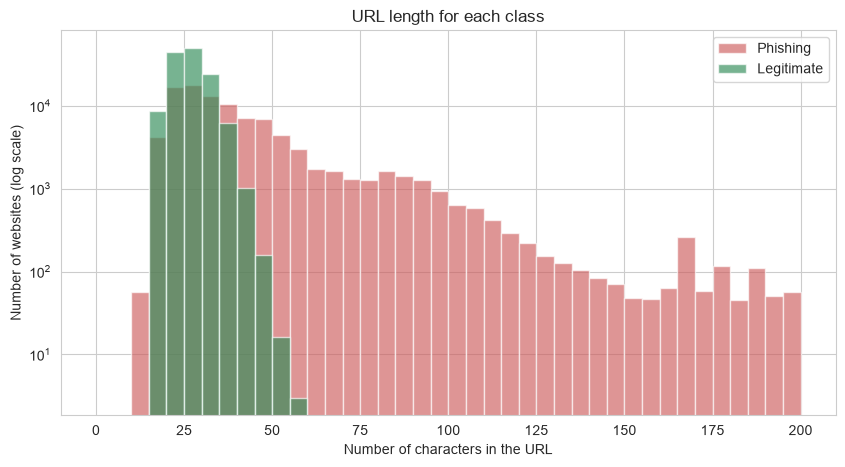

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,100520.0,45.70,61.25,13.0,26.0,34.0,48.0,6097.0
1,134850.0,26.23,4.82,15.0,23.0,26.0,29.0,57.0


In [93]:
bins = np.arange(0, 205, 5)

plt.figure(figsize=(10, 5))
plt.hist(df.loc[df["label"] == 0, "URLLength"], bins=bins, log=True,
         color="indianred", alpha=0.65, label="Phishing")
plt.hist(df.loc[df["label"] == 1, "URLLength"], bins=bins, log=True,
         color="seagreen", alpha=0.65, label="Legitimate")
plt.title("URL length for each class")
plt.xlabel("Number of characters in the URL")
plt.ylabel("Number of websites (log scale)")
plt.legend()
plt.show()

df.groupby("label")["URLLength"].describe().round(2)

- The real websites are short. Half of them are 26 characters or less, and the longest one has only 57 characters.
- The phishing URLs are longer. Half of them are 34 characters or more, and the longest one has 6097 characters. A phishing URL carries extra words and extra parameters, because it tries to copy the name of the brand it is pretending to be.
- The y axis is a log scale, because there are very few very long URLs.

#### Flags in URL and on the page
These four columns are only 0 or 1, so we plot the share of each class where the flag is 1.

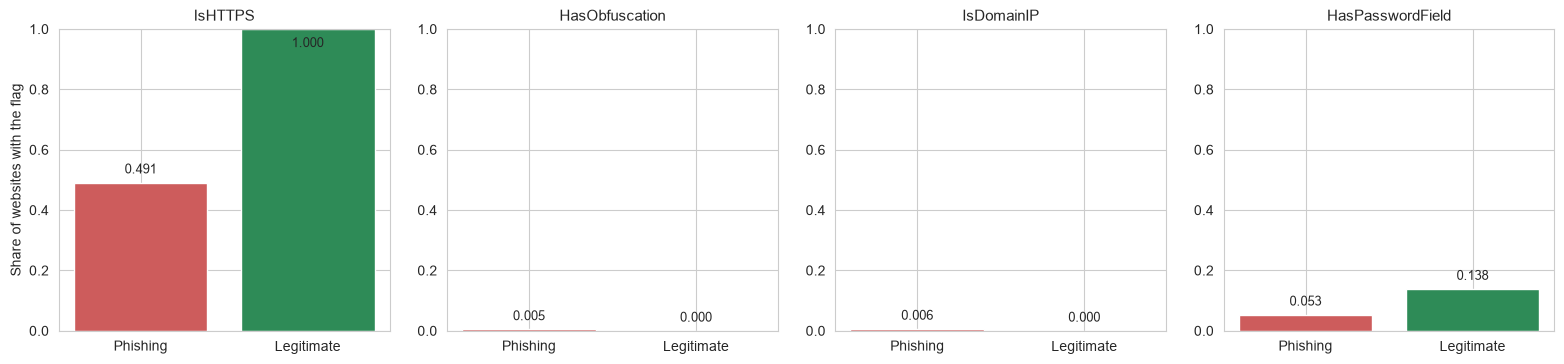

In [94]:
flag_columns = ["IsHTTPS", "HasObfuscation", "IsDomainIP", "HasPasswordField"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].set_ylabel("Share of websites with the flag")

for number in range(4):
    axis = axes[number]
    column = flag_columns[number]

    rates = df.groupby("label")[column].mean()
    axis.bar(CLASS_NAMES, rates.values, color=["indianred", "seagreen"])
    axis.set_title(column, fontsize=11)
    axis.set_ylim(0, 1)
    for position, value in enumerate(rates.values):
        label_height = min(value + 0.03, 0.94)
        axis.text(position, label_height, f"{value:.3f}", ha="center", fontsize=9)

plt.tight_layout(pad=2)
plt.show()

Three things came out of this graph, and two of them surprised us.

- IsHTTPS helps, but only one way round. Every real website uses HTTPS, and only half of the phishing websites do. So no padlock is a warning sign, but a padlock proves nothing, because a certificate is free.
- HasPasswordField is more common on the real websites (0.138) than on the fake ones (0.053). We expected the opposite. We think the phishing pages send the password to another server, so the page has a form but no password box of its own.
- HasObfuscation and IsDomainIP are rare. They appear on 0.005 and 0.006 of the phishing websites, and on none of the real ones. The bars are almost flat, so read the numbers above them. When one of these appears, the website is almost certainly phishing.

#### heat map of the correlations

- A heat map is the easiest way to see a whole correlation matrix at once, because it shows the strong links in both directions without us sorting anything.
- Fifty one features would not fit on one page, so we take the twelve features that relate most to the label, in either direction, and draw the matrix for those twelve plus the label.

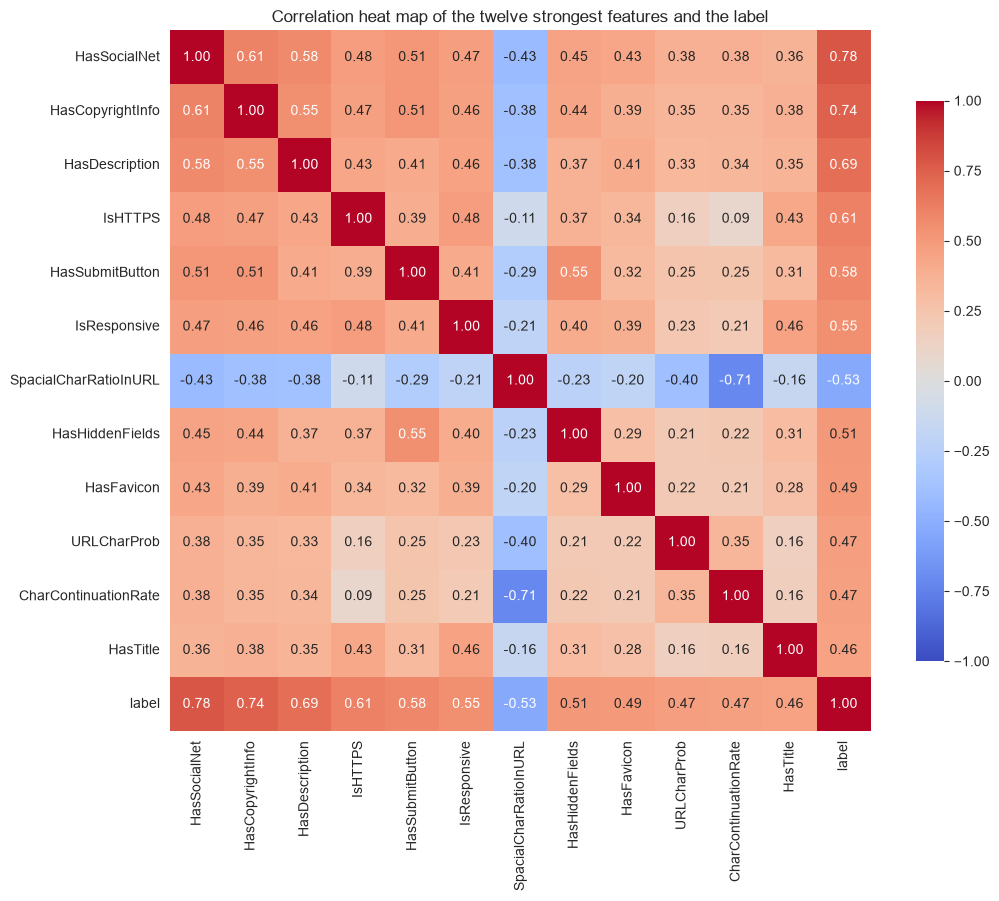

SpacialCharRatioInURL        -0.533
DegitRatioInURL              -0.432
LetterRatioInURL             -0.367
NoOfOtherSpecialCharsInURL   -0.358
DomainLength                 -0.283
NoOfLettersInURL             -0.258
URLLength                    -0.233
NoOfDegitsInURL              -0.178
NoOfQMarkInURL               -0.176
TLDLength                    -0.079
NoOfEqualsInURL              -0.077
NoOfSelfRedirect             -0.077
IsDomainIP                   -0.060
HasObfuscation               -0.053
NoOfURLRedirect              -0.046
ObfuscationRatio             -0.042
LargestLineLength            -0.041
NoOfAmpersandInURL           -0.035
NoOfObfuscatedChar           -0.015
NoOfSubDomain                -0.006
TLDCode                       0.039
NoOfPopup                     0.047
NoOfCSS                       0.068
TLDLegitimateProb             0.097
Crypto                        0.100
NoOfEmptyRef                  0.109
HasPasswordField              0.139
HasExternalFormSubmit       

In [95]:
feature_columns = []
for column in df.columns:
    if column != "label":
        feature_columns.append(column)

correlation_with_label = df[feature_columns].corrwith(df["label"]).sort_values()

# the twelve features with the strongest link to the label, in either direction.
# the three similarity columns stay out, because we remove them in Step 7 anyway.
honest_features = []
for column in feature_columns:
    if column not in SIMILARITY_FEATURES:
        honest_features.append(column)
strongest = df[honest_features].corrwith(df["label"]).abs().sort_values(ascending=False)
strongest = strongest.head(12).index

heat_map_data = df[list(strongest) + ["label"]].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(heat_map_data, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation heat map of the twelve strongest features and the label")
plt.tight_layout()
plt.show()

correlation_with_label.round(3)

- Blue means the two columns move in opposite directions, and red means they move together. The dark squares down the diagonal are each feature against itself, which is always 1.00.
- The bottom row is the label, and it is the row we care about here. The darkest red squares in that row are page features: `HasSocialNet` (0.78), `HasCopyrightInfo` (0.74), `HasDescription` (0.69) and `IsHTTPS` (0.61). A real company website has social links, a copyright line and a description. A page that was made in five minutes usually has none of them.
- Almost every square in that row is red, which tells us that most features lean towards the legitimate class. The one strong blue square is `SpacialCharRatioInURL` at -0.53, so phishing URLs carry more symbols. The printed table under the graph shows the rest: `DegitRatioInURL` is -0.43 and `URLLength` is -0.23, so more digits and more characters also mean more risk, but neither is as strong as the page features.
- The squares away from the label row and column are useful too, because they show features that repeat each other. `HasSubmitButton` and `HasHiddenFields` sit at 0.55, since both describe a form, and `IsHTTPS` and `IsResponsive` move together. That matters for naive Bayes, as we explain in Step 6.
- So both kinds of feature carry information. That is already part of the answer to question 2.

---
# Step 04: *Choosing the features (R2)*
---

- We use every row. An earlier version of this notebook took a sample of 24,000 rows, because a language model had to encode every URL and that was slow. That model is gone, so the sample has no reason to stay. All 235,370 rows train in about a minute on a laptop.

- That also means no rounding and no wasted data. The scores below are measured on the whole dataset.

- Step 3 removed 425 duplicate URLs, and all of them were phishing rows, so the phishing count here is 100,520 instead of the 100,945 in the raw file.

In [96]:
data = df.copy()

print("Rows we use:", len(data))
print(data["label"].value_counts())

Rows we use: 235370
label
1    134850
0    100520
Name: count, dtype: int64


#### Two ways to rank the features
We use two methods, and then we add their ranks together.

- The first method is the correlation with the label, which we already have from Step 3. It only finds a straight line relation, so it misses some things.

- The second method is the random forest importance. A forest can tell us how much each feature helped it to split the data. This one also finds relations that are not a straight line.

- A feature that does well in both methods is probably a good feature.

In [97]:
from sklearn.ensemble import RandomForestClassifier

feature_columns = []
for column in data.columns:
    if column != "label":
        feature_columns.append(column)

forest = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
forest.fit(data[feature_columns], data["label"])

correlation = data[feature_columns].corrwith(data["label"]).abs()

importance_table = pd.DataFrame({
    "Feature": feature_columns,
    "Correlation": correlation.reindex(feature_columns).values,
    "RandomForest": forest.feature_importances_,
})

importance_table["Score"] = (
    importance_table["Correlation"].rank(ascending=False)
    + importance_table["RandomForest"].rank(ascending=False)
)

importance_table = importance_table.sort_values("Score").reset_index(drop=True)
importance_table.head(20).round(4)

,Feature,Correlation,RandomForest,Score
0,URLSimilarityIndex,0.8603,0.1811,2.0
1,HasSocialNet,0.7839,0.0479,9.0
2,HasCopyrightInfo,0.7432,0.0404,12.0
3,HasDescription,0.6900,0.0216,15.0
4,IsHTTPS,0.6103,0.0165,17.0
5,IsResponsive,0.5490,0.0090,22.0
6,DomainTitleMatchScore,0.5842,0.0074,23.0
7,NoOfJS,0.3732,0.0854,24.0
8,NoOfSelfRef,0.3159,0.0972,26.0
9,HasSubmitButton,0.5788,0.0060,27.0


#### The features we used
- We keep the best twenty features, and then we remove the three similarity columns from Step 1. That leaves seventeen features.

- As we said in Step 1, those three columns are almost a copy of the label, so a model that uses them gets a very high score for the wrong reason. Seventeen honest features is better than twenty features and a fake score.

In [98]:
top_twenty = importance_table.head(20)["Feature"].tolist()
SELECTED_FEATURES = []
for feature in top_twenty:
    if feature not in SIMILARITY_FEATURES:
        SELECTED_FEATURES.append(feature)

print("Best twenty features:", len(top_twenty))
print("Features we use:", len(SELECTED_FEATURES))
for number, feature in enumerate(SELECTED_FEATURES, start=1):
    print(number, feature)

Best twenty features: 20
Features we use: 17
1 HasSocialNet
2 HasCopyrightInfo
3 HasDescription
4 IsHTTPS
5 IsResponsive
6 NoOfJS
7 NoOfSelfRef
8 HasSubmitButton
9 NoOfExternalRef
10 LineOfCode
11 NoOfImage
12 NoOfOtherSpecialCharsInURL
13 DegitRatioInURL
14 SpacialCharRatioInURL
15 HasHiddenFields
16 HasFavicon
17 LetterRatioInURL


#### Best of these features
This graph shows only the seventeen features we keep, in the order of their random forest importance, so it matches the input of the models.


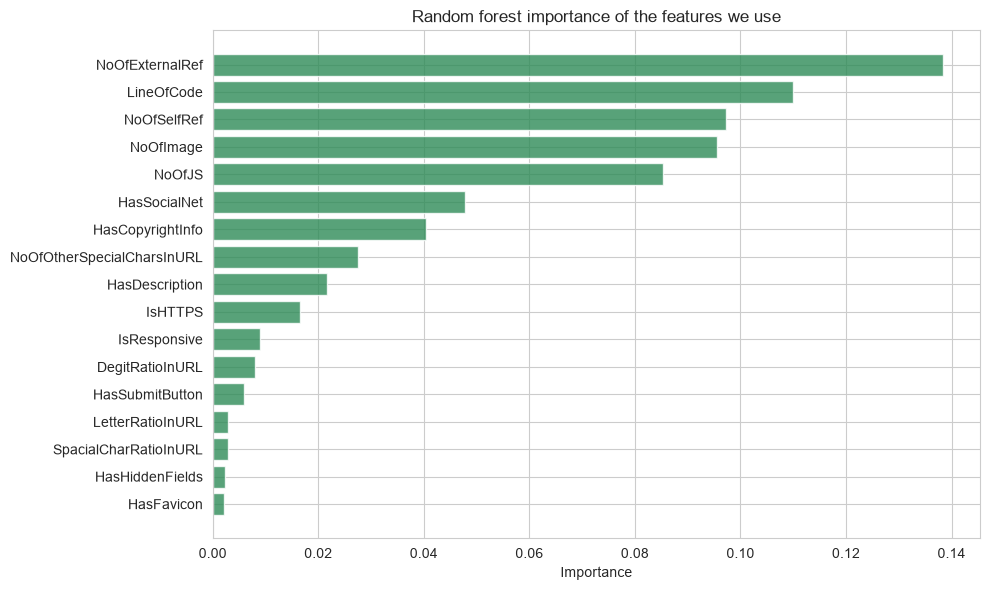

In [99]:
plot_table = importance_table[importance_table["Feature"].isin(SELECTED_FEATURES)]
plot_table = plot_table.sort_values("RandomForest")

plt.figure(figsize=(10, 6))
plt.barh(plot_table["Feature"], plot_table["RandomForest"], color="seagreen", alpha=0.8)
plt.title("Random forest importance of the features we use")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

- The order answers our second question. The page features come first: NoOfExternalRef, LineOfCode, NoOfSelfRef, NoOfImage and NoOfJS. A real website loads its own pictures and scripts. A fake page borrows them from somewhere else.

- The URL features are much lower. Only two of them, SpacialCharRatioInURL and DegitRatioInURL, are in the twenty.

- URLLength did not reach the twenty at all. That surprised us, because it looked important in the correlation graph in Step 6. A feature can have a strong correlation and still not help a tree, and this is why we used two methods instead of one.

## Training and testing the data for the tabular dataset (R2)
- We split the data into 70 percent for training and 30 percent for testing. The split keeps the same class balance in both parts, which is called a stratified split.

- We only use the test part for the final scores. We never use it to choose anything, because that would make the scores look better than they really are.

- We also scale the features, which means we subtract the mean and divide by the standard deviation. Logistic regression, k nearest neighbours and the neural network need it. The trees do not need it, but it does not hurt them.

- We fit the scaler on the training rows only. If we fit it on all the rows, information about the test rows would get into the training.

In [100]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train_frame, X_test_frame, y_train, y_test = train_test_split(
    data[SELECTED_FEATURES], data["label"],
    test_size=TEST_SIZE, stratify=data["label"], random_state=RANDOM_STATE
)

print("Selected features columns:", SELECTED_FEATURES, "\n")
print("Training size/rows:", len(X_train_frame))
print("Test size/rows:", len(X_test_frame))

Selected features columns: ['HasSocialNet', 'HasCopyrightInfo', 'HasDescription', 'IsHTTPS', 'IsResponsive', 'NoOfJS', 'NoOfSelfRef', 'HasSubmitButton', 'NoOfExternalRef', 'LineOfCode', 'NoOfImage', 'NoOfOtherSpecialCharsInURL', 'DegitRatioInURL', 'SpacialCharRatioInURL', 'HasHiddenFields', 'HasFavicon', 'LetterRatioInURL'] 

Training size/rows: 164759
Test size/rows: 70611


#### Scaling our dataseet
Using StandardScaler from sklearn

In [101]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_frame)
X_test = scaler.transform(X_test_frame)

print(X_train.shape)
print(X_test.shape)

(164759, 17)
(70611, 17)


---
# Step 05: *Clustering (R2)*

In this step we do not give the labels to the algorithm. It has to group the data on its own. Afterwards we compare its groups with the real classes, to see if it found the same thing.

We try two algorithms from the lectures.

- `K-Means` puts each row in the group of the nearest centre.
- A Gaussian mixture uses the `EM` algorithm. It fits two Gaussian distributions and gives each row a probability for each one.

---

#### How many groups?
- We try k from 2 to 8 and look at two numbers.

- Inertia is the total distance from the rows to their centre. It always goes down when k goes up, so we look at where the line bends.

- The silhouette score says if the rows are close to their own group and far from the next group. A higher score is better.

In [102]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_results = []

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = kmeans.fit_predict(X_train)
    score = silhouette_score(X_train, labels, sample_size=5000, random_state=RANDOM_STATE)

    cluster_results.append({"k": k, "Inertia": kmeans.inertia_, "Silhouette": score})

cluster_results = pd.DataFrame(cluster_results)
cluster_results.round(3)

,k,Inertia,Silhouette
0,2,2077261.839,0.310
1,3,1919608.285,0.274
2,4,1806339.152,0.193
3,5,1689672.814,0.197
4,6,1599768.938,0.204
5,7,1545901.331,0.205
6,8,1476550.336,0.209


The bend in the inertia line is at k = 2, and the silhouette score is also highest at k = 2. Every bigger k gives a lower score. So we use two groups, which is also the number we can compare with the two real classes.

#### K-Means and the Gaussian mixture


In [103]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.mixture import GaussianMixture

kmeans = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_train)

# the first try put one group on a single row, so we ask for five starts and keep the best
mixture = GaussianMixture(n_components=2, n_init=5, random_state=RANDOM_STATE)
mixture_labels = mixture.fit_predict(X_train)

results = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Adjusted Rand index": adjusted_rand_score(y_train, kmeans_labels),
        "Mutual information": normalized_mutual_info_score(y_train, kmeans_labels),
        "Group sizes": str(np.bincount(kmeans_labels)),
    },
    {
        "Algorithm": "Gaussian mixture (EM)",
        "Adjusted Rand index": adjusted_rand_score(y_train, mixture_labels),
        "Mutual information": normalized_mutual_info_score(y_train, mixture_labels),
        "Group sizes": str(np.bincount(mixture_labels)),
    },
])

results.round(3)

,Algorithm,Adjusted Rand index,Mutual information,Group sizes
0,K-Means,0.892,0.824,[91392 73367]
1,Gaussian mixture (EM),0.985,0.965,[69889 94870]


We use two scores here.

- The adjusted Rand index says how well the groups match the real classes. 1 is a perfect match and 0 is the same as guessing.
- Mutual information says how much the group of a row tells us about its label. 0 means nothing and 1 means everything.
- On our first try the mixture put one group on a single row and every other row in the other group. That scores 0 on the adjusted Rand index, even though the two groups look tidy. So we gave it five different starts and kept the best one, and then it found the two classes.
- Both algorithms now do much better than our third hypothesis expected. The next table shows why.

In [104]:
pd.crosstab(kmeans_labels, y_train.values, rownames=["Group"], colnames=["True label"])

True label,0,1
Group,,
0,785,90607
1,69579,3788


- Each group is almost one whole class. The difference between phishing and legitimate is the biggest difference in this data, so an algorithm that only looks for big differences finds it easily.
- We have to be careful with this result. A high score does not mean that clustering can detect phishing. It means that this sample is clean, so the two classes sit in two separate areas. On real internet traffic the areas overlap, and the algorithm would not know which group is the dangerous one. Clustering can describe groups. Only a model that has seen the labels can say which group is bad.

---
# Step 06: *Classical Models (R3)*

The coursework asks for at least three algorithms. We train five, because they are quick and we
wanted to compare them.

| Model | Type | Why we chose it |
|---|---|---|
| Gaussian Naive Bayes | generative | The naive Bayes from the lectures. Very fast. |
| Logistic Regression | discriminative, linear | The standard linear model. |
| k Nearest Neighbours | instance based | Looks at the nearest rows and assumes no shape for the boundary. |
| Decision Tree | rules | The rules can be read. Step 11 looks at this one in more detail. |
| Random Forest | ensemble | Many trees together, so the mistakes of one tree cancel out. |

So the notebook has both generative and discriminative models, which section 2 of the
coursework asks for.

For the scores, we use the four metrics the coursework names.

- Accuracy is the share of correct answers.
- Precision says how many of the websites we called phishing really were phishing.
- Recall says how many of the real phishing websites we caught.
- F1 combines precision and recall, which helps when the two disagree.

We do not use accuracy on its own, because the classes are 57 and 43 percent. A model can get a
good accuracy by always answering the same thing.

---

In [105]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [106]:
# model dictionary for 6 models 

models = {
    "Gaussian Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "k Nearest Neighbours": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}

In [107]:
rows = []
trained_models = {}

In [108]:
# Training the models

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
    })
    trained_models[name] = model
    print("Finished:", name)

Finished: Gaussian Naive Bayes
Finished: Logistic Regression
Finished: k Nearest Neighbours
Finished: Decision Tree
Finished: Random Forest


In [109]:
classical_results = pd.DataFrame(rows).set_index("Model").sort_values("F1", ascending=False)
classical_results.round(4)

,Accuracy,Precision,Recall,F1
Model,,,,
Random Forest,0.9995,0.9994,0.9998,0.9996
Decision Tree,0.9986,0.9989,0.9986,0.9988
Logistic Regression,0.9984,0.9983,0.9989,0.9986
k Nearest Neighbours,0.9978,0.9976,0.9986,0.9981
Gaussian Naive Bayes,0.9944,0.9922,0.9980,0.9951


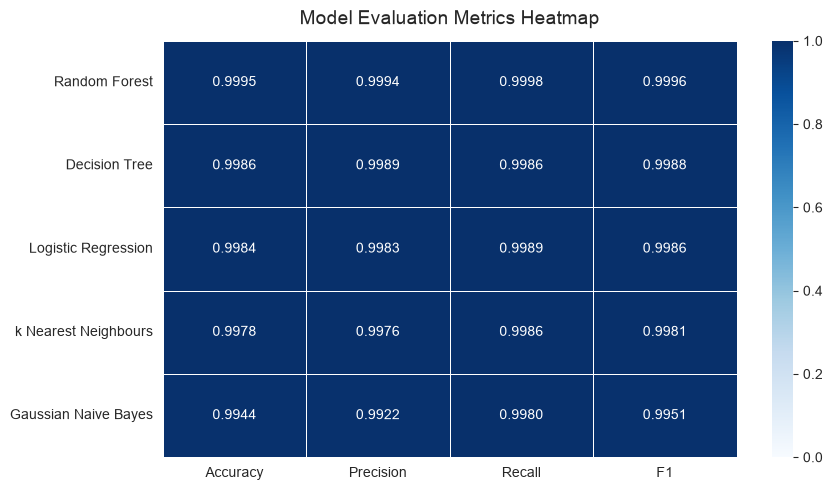

In [110]:
plt.figure(figsize=(9, 5))
sns.heatmap(
    classical_results,
    annot=True,
    fmt=".4f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5
)

plt.title("Model Evaluation Metrics Heatmap", fontsize=14, pad=12)
plt.ylabel("")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

- Every model is above 99 percent accuracy, so our first hypothesis is correct, and the task is
much easier than we expected.

- The two ensembles are at the top of this table. Gaussian naive Bayes is last, because it assumes
that the features do not depend on each other, and in this dataset many of them do. For example
the counts of self references, external references and empty references all describe the same
page.

---
# Step 07: *Decision Tree (R3)*

The coursework also asks us to discuss what decision trees are good for with this dataset.

### The rules the tree learns

A deep tree gives hundreds of rules and nobody can read them. So we train a small tree with a
depth of three. Every rule then fits on one line.

---

In [111]:
from sklearn.tree import export_text, plot_tree

small_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
small_tree.fit(X_train, y_train)

print("Accuracy of the small tree:", round(small_tree.score(X_test, y_test), 4))
print()
print(export_text(small_tree, feature_names=SELECTED_FEATURES, max_depth=3))

Accuracy of the small tree: 0.9896

|--- NoOfExternalRef <= -0.29
|   |--- NoOfSelfRef <= -0.35
|   |   |--- HasSocialNet <= 0.09
|   |   |   |--- class: 0
|   |   |--- HasSocialNet >  0.09
|   |   |   |--- class: 1
|   |--- NoOfSelfRef >  -0.35
|   |   |--- LineOfCode <= -0.30
|   |   |   |--- class: 0
|   |   |--- LineOfCode >  -0.30
|   |   |   |--- class: 1
|--- NoOfExternalRef >  -0.29
|   |--- NoOfOtherSpecialCharsInURL <= 0.31
|   |   |--- IsHTTPS <= -0.69
|   |   |   |--- class: 0
|   |   |--- IsHTTPS >  -0.69
|   |   |   |--- class: 1
|   |--- NoOfOtherSpecialCharsInURL >  0.31
|   |   |--- NoOfSelfRef <= -0.21
|   |   |   |--- class: 0
|   |   |--- NoOfSelfRef >  -0.21
|   |   |   |--- class: 1



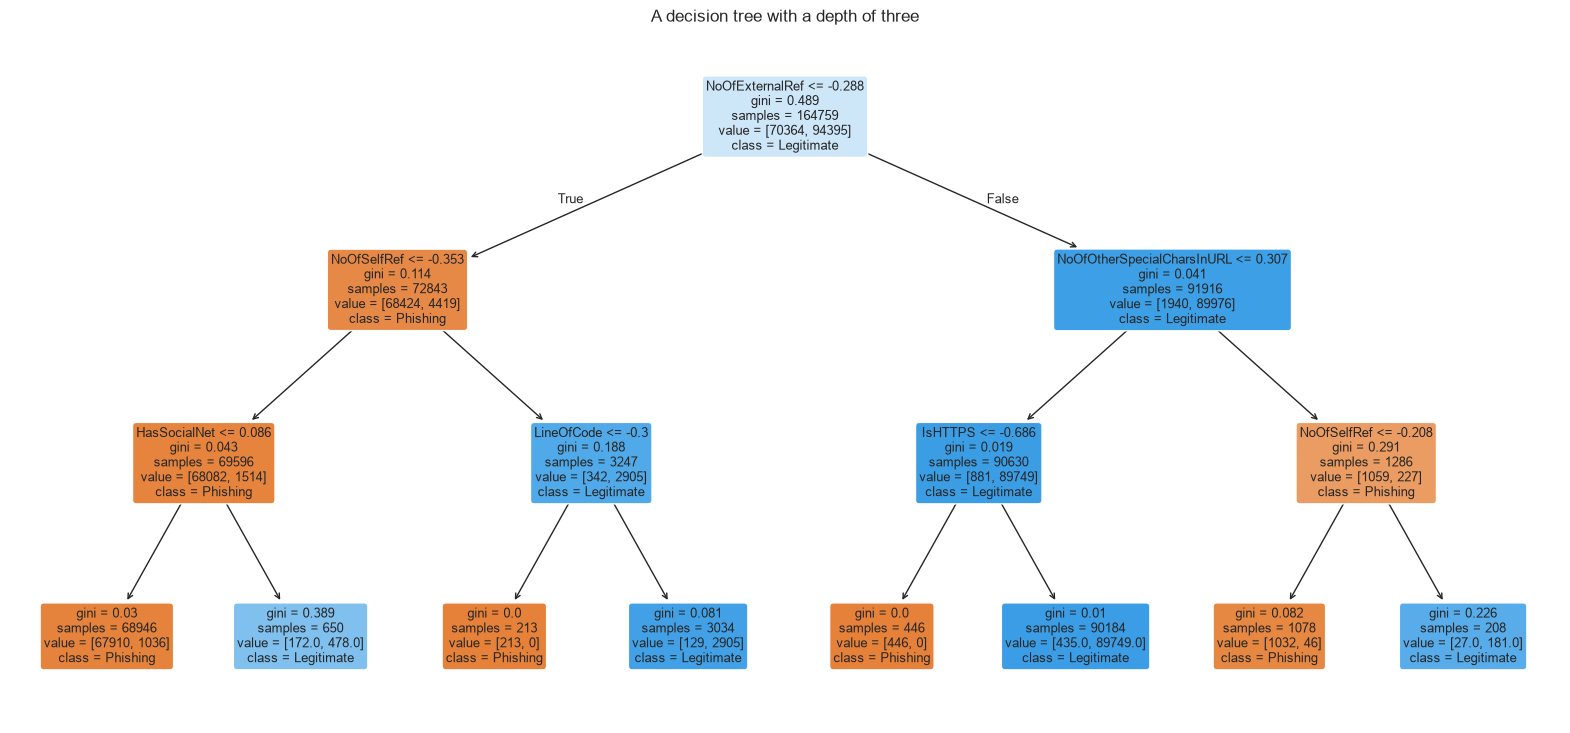

In [112]:
plt.figure(figsize=(20, 9))
plot_tree(small_tree, feature_names=SELECTED_FEATURES, class_names=CLASS_NAMES,
          filled=True, rounded=True, fontsize=9, max_depth=3)
plt.title("A decision tree with a depth of three")
plt.show()

Three questions are enough to reach `0.9896` accuracy, which is close to the ensembles. Most of
the questions are things an analyst can read: how many of its own references the page has, how
much code it has, how many of its own pictures it loads, and how many symbols its URL carries.

That is the main reason to use a decision tree for this problem.

1. It explains itself. If the system blocks a website, we can show the customer the exact
   questions that caused the block. That is hard to do with a random forest.
2. It is fast. The tree trains in less than one second, so it is a good first model to try
   before spending time on a neural network.
3. The rules can be written as simple `if` statements. Those can run inside a mail filter or a
   browser extension, where a neural network cannot go.
4. It needs no scaling, and it handles a mix of yes/no flags and counts, which is exactly what
   this dataset holds.

#### Where the tree is weak

A tree with no depth limit memorises the training rows. The table below shows the training
score and the test score for the tree models.


In [113]:
tree_check = pd.DataFrame([
    {
        "Model": "Decision Tree, no depth limit",
        "Training accuracy": trained_models["Decision Tree"].score(X_train, y_train),
        "Test accuracy": trained_models["Decision Tree"].score(X_test, y_test),
    },
    {
        "Model": "Decision Tree, depth three",
        "Training accuracy": small_tree.score(X_train, y_train),
        "Test accuracy": small_tree.score(X_test, y_test),
    },
    {
        "Model": "Random Forest, 300 trees",
        "Training accuracy": trained_models["Random Forest"].score(X_train, y_train),
        "Test accuracy": trained_models["Random Forest"].score(X_test, y_test),
    },
])

tree_check.round(4)

,Model,Training accuracy,Test accuracy
0,"Decision Tree, no depth limit",1.0000,0.9986
1,"Decision Tree, depth three",0.9888,0.9896
2,"Random Forest, 300 trees",1.0000,0.9995


- The tree with no depth limit gets every training row right. That is memorising, not learning,
and it is why the depth limit exists. A forest averages many trees, so the mistakes of one
tree cancel out against the others.

- A tree also cannot express a smooth rule like "length matters more when the URL has many sub
domains" without many extra questions.


---
# Step 08: *Neural Networks (R4)*
We train two networks, which are the two kinds the brief names.

| Network | Input | Question |
|---|---|---|
| Multi layer perceptron | the seventeen features of the table | Does a neural network beat the classical models on the same input? |
| Two dimensional CNN | the screenshots of the pages | Can the picture of a page be spotted as fake on its own? |

---

## The multi layer perceptron

- A multi layer perceptron is a few layers of nodes with a non linear function between them.
The number of layers and the number of nodes in each layer is our choice, so we try four
shapes and keep the best one.
- We also use two settings to stop the model from memorising the training data. `alpha` is a
penalty on large weights, and `early_stopping` stops the training when the validation loss
stops improving.

---

In [117]:
from sklearn.neural_network import MLPClassifier

# looping and testing through each number of possible number of neurons
shapes = [(32,), (64, 32), (128, 64), (64, 32, 16)]

tuning_rows = []

In [118]:
for shape in shapes:
    trial = MLPClassifier(
        hidden_layer_sizes=shape,
        activation="relu",
        alpha=0.0001,
        batch_size=256,
        max_iter=200,
        early_stopping=True,
        n_iter_no_change=10,
        random_state=RANDOM_STATE,
    )
    trial.fit(X_train, y_train)

    tuning_rows.append({
        "Hidden layers": str(shape),
        "F1 on the test rows": f1_score(y_test, trial.predict(X_test)),
    })

In [119]:
tuning_table = pd.DataFrame(tuning_rows)
tuning_table.round(4)

,Hidden layers,F1 on the test rows
0,"(32,)",0.9995
1,"(64, 32)",0.9996
2,"(128, 64)",0.9995
3,"(64, 32, 16)",0.9997



- All four shapes land between 0.9995 and 0.9997, so the shape of the network hardly matters on
this data. The three layer shape is the best by a small margin, so we use `(64, 32, 16)`.


In [ ]:
# Final MLP model using (64, 32, 16) sets of neurons

mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32, 16),
    activation="relu",
    alpha=0.0001,
    batch_size=256,
    max_iter=200,
    early_stopping=True,
    n_iter_no_change=10,
    random_state=RANDOM_STATE,
)

mlp.fit(X_train, y_train)
print("Epochs before early stopping:", mlp.n_iter_)

---
# Step 09: *Final Comparison and the Conclusion (R4)*
---